# PRIM — When does adding facility pooling to ambulance pooling help or hurt?

Compare (fac=1, amb=1) vs (fac=0, amb=1).
Find the parameter box where combining both policies produces worse T1 mortality
than ambulance pooling alone.

In [16]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ema_workbench.analysis import prim

RESULTS_PATH = _root / "data_cluster" / "20260605_212356_scenario_2btg_pooling_limit_baseline_stove" / "results.csv"
df = pd.read_csv(RESULTS_PATH)
print(f"Loaded {len(df)} runs")

UNCERTAINTIES = ["ccp_r1_same_bn_min", "bcas_rate", "waves_per_day", "wave_duration_min"]

amb = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 1)].sort_values("scenario").reset_index(drop=True)
both = df[(df["facility_eligibility"] == 1) & (df["ambulance_eligibility"] == 1)].sort_values("scenario").reset_index(drop=True)
assert (amb["scenario"].values == both["scenario"].values).all()

merged = amb[UNCERTAINTIES].copy()
merged["mort_amb"] = amb["death_rate_T1_BCAS"].values
merged["mort_both"] = both["death_rate_T1_BCAS"].values
merged["delta"] = merged["mort_both"] - merged["mort_amb"]

print(f"Matched scenarios: {len(merged)}")
print(f"Delta range: {merged['delta'].min():.4f} to {merged['delta'].max():.4f}")
print(f"Median delta: {merged['delta'].median():.4f}")
print(f"Both worse: {(merged['delta'] > 0.01).sum()} / {len(merged)} ({(merged['delta'] > 0.01).mean():.1%})")
print(f"Both better: {(merged['delta'] < -0.01).sum()} / {len(merged)} ({(merged['delta'] < -0.01).mean():.1%})")
print(f"Neutral: {((merged['delta'] >= -0.01) & (merged['delta'] <= 0.01)).sum()} / {len(merged)}")

Loaded 40960 runs
Matched scenarios: 10240
Delta range: -0.5714 to 0.5000
Median delta: 0.0000
Both worse: 578 / 10240 (5.6%)
Both better: 3672 / 10240 (35.9%)
Neutral: 5990 / 10240


## Distribution of delta (both − amb)

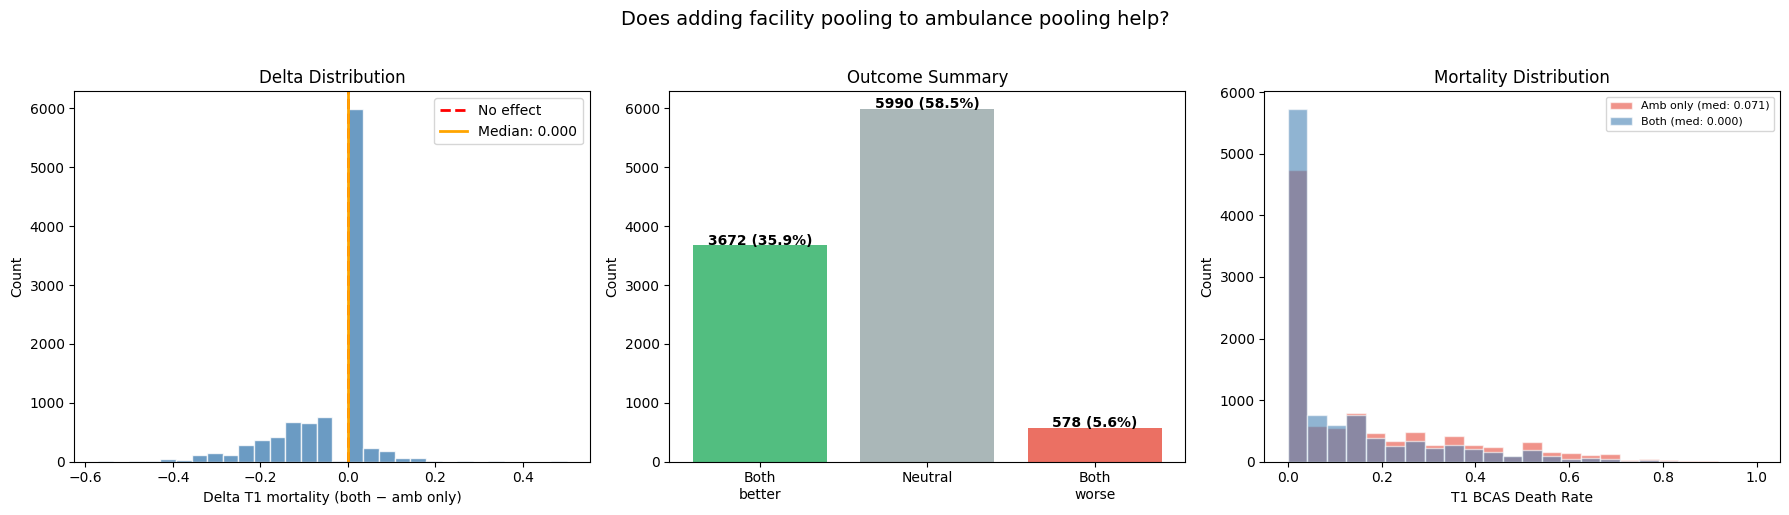

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Histogram
axes[0].hist(merged["delta"], bins=30, color="steelblue", alpha=0.8, edgecolor="white")
axes[0].axvline(0, color="red", linewidth=2, linestyle="--", label="No effect")
axes[0].axvline(merged["delta"].median(), color="orange", linewidth=2, label=f"Median: {merged['delta'].median():.3f}")
axes[0].set_xlabel("Delta T1 mortality (both − amb only)")
axes[0].set_ylabel("Count")
axes[0].set_title("Delta Distribution")
axes[0].legend()

# Bar chart
n_better = (merged["delta"] < -0.01).sum()
n_neutral = ((merged["delta"] >= -0.01) & (merged["delta"] <= 0.01)).sum()
n_worse = (merged["delta"] > 0.01).sum()
bars = axes[1].bar(["Both\nbetter", "Neutral", "Both\nworse"],
                    [n_better, n_neutral, n_worse],
                    color=["#27ae60", "#95a5a6", "#e74c3c"], alpha=0.8)
for bar, val in zip(bars, [n_better, n_neutral, n_worse]):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
                 f"{val} ({val/len(merged):.1%})", ha="center", fontweight="bold")
axes[1].set_ylabel("Count")
axes[1].set_title("Outcome Summary")

# Overlapping distributions
bins = np.linspace(0, 1, 25)
axes[2].hist(merged["mort_amb"], bins=bins, alpha=0.6, color="#e74c3c", edgecolor="white",
             label=f"Amb only (med: {merged['mort_amb'].median():.3f})")
axes[2].hist(merged["mort_both"], bins=bins, alpha=0.6, color="steelblue", edgecolor="white",
             label=f"Both (med: {merged['mort_both'].median():.3f})")
axes[2].set_xlabel("T1 BCAS Death Rate")
axes[2].set_ylabel("Count")
axes[2].set_title("Mortality Distribution")
axes[2].legend(fontsize=8)

fig.suptitle("Does adding facility pooling to ambulance pooling help?", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## PRIM — Where does adding facility pooling hurt?

Cases where both is worse than amb only: 578 / 10240 (5.6%)

Box where adding fac pooling HURTS:
coverage        1.000000
density         0.056445
id              0.000000
k             578.000000
mass            1.000000
mean            0.056445
n           10240.000000
res_dim         0.000000
Name: 0, dtype: float64

Empty DataFrame
Columns: [(box 0, min), (box 0, max), (box 0, qp value), (box 0, qp value)]
Index: []


C:\Users\User\Documents\thesis\medevac_model\.venv\Lib\site-packages\ema_workbench\analysis\scenario_discovery_util.py:555: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim(top=-0.5, bottom=nr_unc - 0.5)


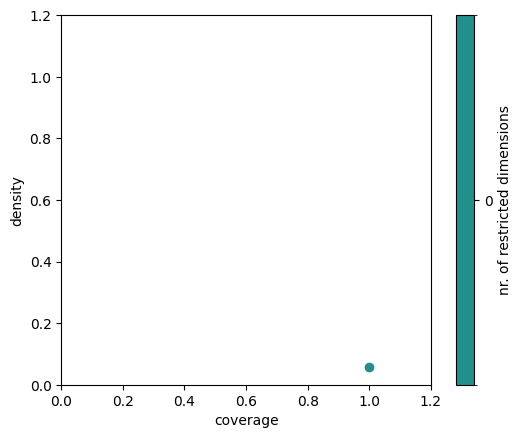

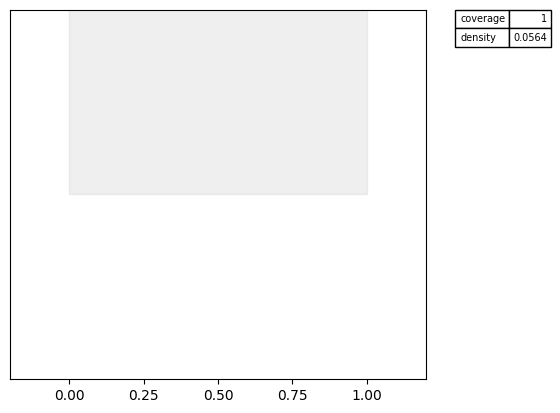

In [18]:
x = merged[UNCERTAINTIES].astype(float)
y_hurt = merged["delta"].values > 0.01

print(f"Cases where both is worse than amb only: {y_hurt.sum()} / {len(y_hurt)} ({y_hurt.mean():.1%})")

if y_hurt.sum() >= 10:
    p_hurt = prim.Prim(x, y_hurt, threshold=0.5)
    box_hurt = p_hurt.find_box()
    box_hurt.show_tradeoff()
    print("\nBox where adding fac pooling HURTS:")
    box_hurt.inspect(style="graph")
    box_hurt.inspect()
else:
    print("Too few cases for PRIM.")

## PRIM — Where does adding facility pooling help?

Cases where both is better than amb only: 3672 / 10240 (35.9%)

Box where adding fac pooling HELPS:
coverage      0.155501
density       0.780055
id           33.000000
k           571.000000
mass          0.071484
mean          0.780055
n           732.000000
res_dim       4.000000
Name: 33, dtype: float64

                       box 33                                       
                          min        max      qp value      qp value
wave_duration_min    1.000000  26.500000           NaN  2.647922e-10
ccp_r1_same_bn_min  10.000000  16.500000           NaN  5.720980e-04
waves_per_day        1.000000   3.500000           NaN  2.322058e-03
bcas_rate            0.039388   0.069998  4.652835e-42           NaN


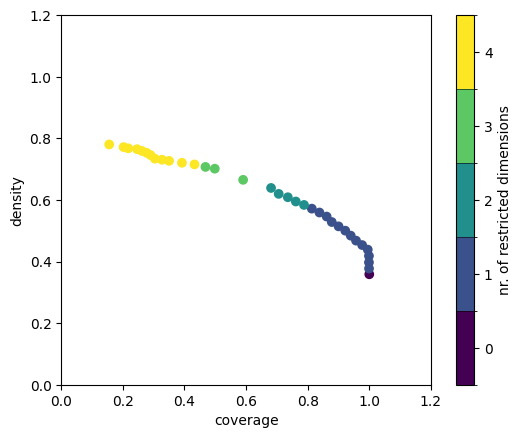

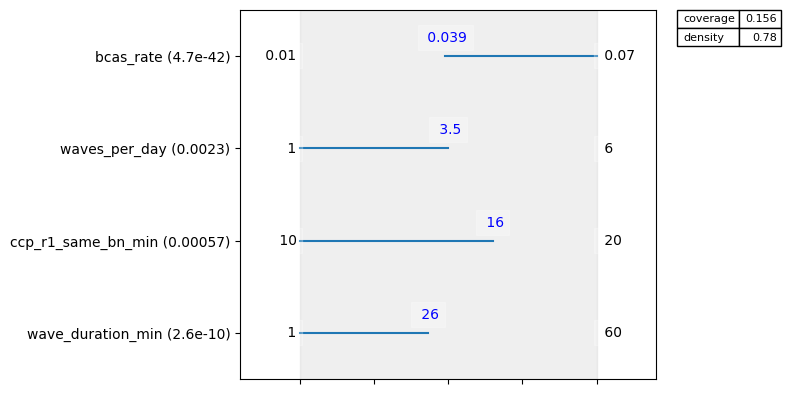

In [19]:
y_help = merged["delta"].values < -0.01

print(f"Cases where both is better than amb only: {y_help.sum()} / {len(y_help)} ({y_help.mean():.1%})")

if y_help.sum() >= 10:
    p_help = prim.Prim(x, y_help, threshold=0.5)
    box_help = p_help.find_box()
    box_help.show_tradeoff()
    print("\nBox where adding fac pooling HELPS:")
    box_help.inspect(style="graph")
    box_help.inspect()
else:
    print("Too few cases for PRIM.")

## Delta vs Each Uncertainty

C:\Users\User\AppData\Local\Temp\ipykernel_22936\3458769358.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=labels, patch_artist=True, widths=0.6)
C:\Users\User\AppData\Local\Temp\ipykernel_22936\3458769358.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=labels, patch_artist=True, widths=0.6)
C:\Users\User\AppData\Local\Temp\ipykernel_22936\3458769358.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=labels, patch_artist=True, widths=0.6)
C:\Users\User\AppData\Local\Temp\ipykernel_22936\3458769358.py:9: MatplotlibDeprecati

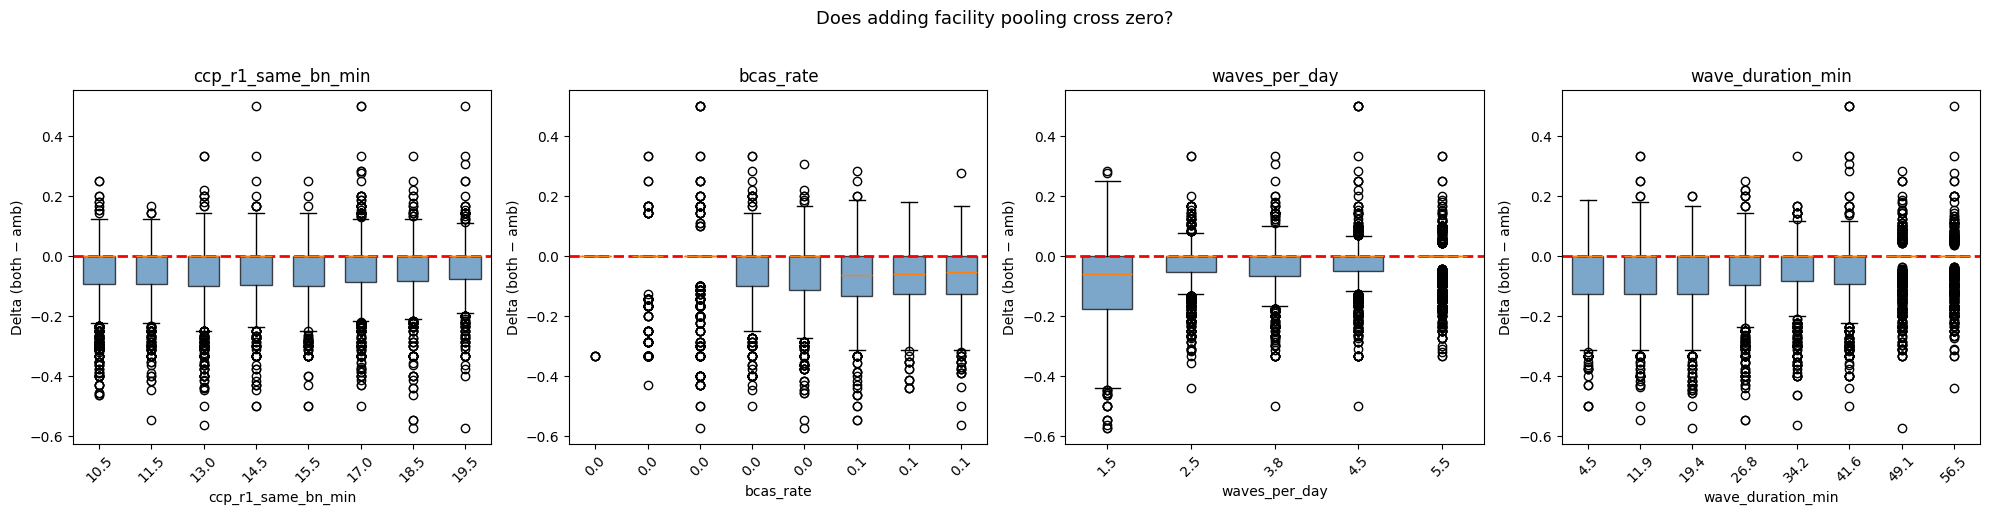

In [20]:
fig, axes = plt.subplots(1, len(UNCERTAINTIES), figsize=(5 * len(UNCERTAINTIES), 5))

for ax, col in zip(axes, UNCERTAINTIES):
    bins = pd.qcut(merged[col], q=8, duplicates="drop")
    groups = merged.groupby(bins, observed=True)
    labels = [f"{iv.mid:.1f}" for iv in groups.groups.keys()]
    data = [g["delta"].values for _, g in groups]

    bp = ax.boxplot(data, labels=labels, patch_artist=True, widths=0.6)
    for patch in bp["boxes"]:
        patch.set_facecolor("steelblue")
        patch.set_alpha(0.7)
    ax.axhline(0, color="red", linewidth=2, linestyle="--")
    ax.set_xlabel(col)
    ax.set_ylabel("Delta (both − amb)")
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)

fig.suptitle("Does adding facility pooling cross zero?", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()